<a href="https://colab.research.google.com/github/alejopachoncortes/taller-pandas-olimpiadas-grupoX/blob/graficos/Proyecto_pandas_graficos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Sección 4: gráficos.
**Nota:** Recuerde cargar los archivos .csv dentro de una carpeta llamada Datos antes de correr el código.   
# Secciones anteriores.

In [3]:
# Creación datasets iniciales.
import pandas as pd
athlete_events = pd.read_csv("Datos/athlete_events.csv")
noc_regions = pd.read_csv("Datos/noc_regions.csv")

In [4]:
# Limpieza de datos.
import math
import matplotlib.pyplot as plt
import numpy as np
athlete_events["Age"] = athlete_events["Age"].fillna(np.mean(athlete_events.Age))
athlete_events["Height"] = athlete_events["Height"].fillna(np.mean(athlete_events.Height))
athlete_events["Weight"] = athlete_events["Weight"].fillna(np.mean(athlete_events.Weight))

In [5]:
# Nuevas variables y fusión de los datasets.
athlete_events['IMC'] = athlete_events['Weight'] / (athlete_events['Height']/100) ** 2

fusionado = athlete_events.merge(noc_regions, how='left', on='NOC')

fusionado['medalla'] = fusionado['Medal'].isin(['Gold', 'Silver', 'Bronze']).astype(int)

# 13)
# Gráfico 1: Genero y Año.

<Axes: xlabel='Year'>

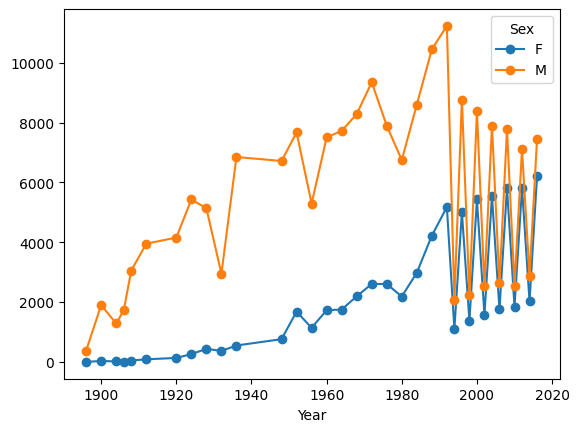

In [6]:
grafico1 = fusionado.groupby(["Year", "Sex"]).size().unstack(fill_value=0)
grafico1.plot(marker="o")

## Gráfico 2: IMC y Deporte.

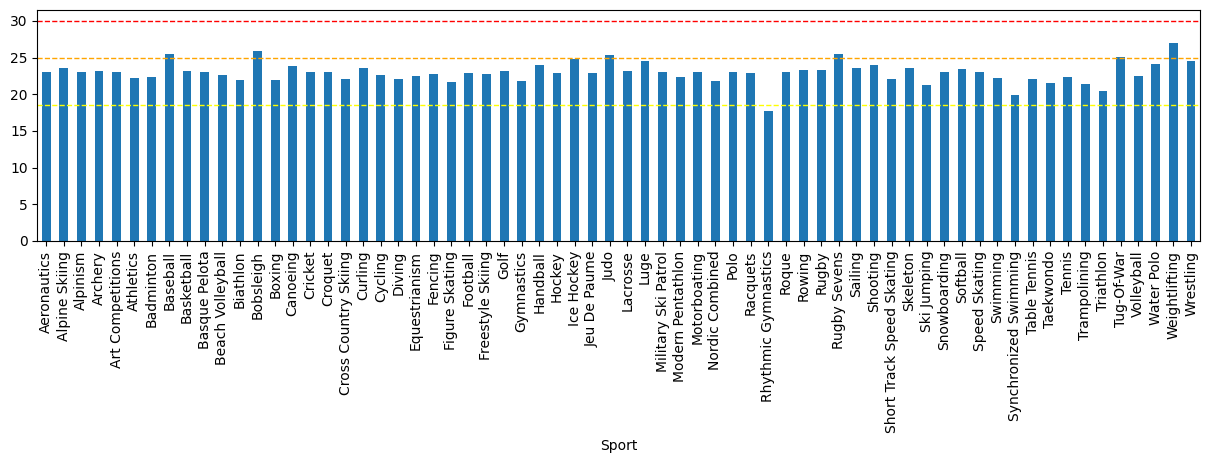

In [7]:
grafico2 = fusionado.groupby("Sport")
plot2 = grafico2["IMC"].mean().plot.bar(figsize=(15,3))
plot2.axhline(y=18.5, color='yellow', linestyle='--', linewidth=1)
plot2.axhline(y=25, color='orange', linestyle='--', linewidth=1)
plot2.axhline(y=30, color='red', linestyle='--', linewidth=1)

## Gráfico 3: País y Medallas.

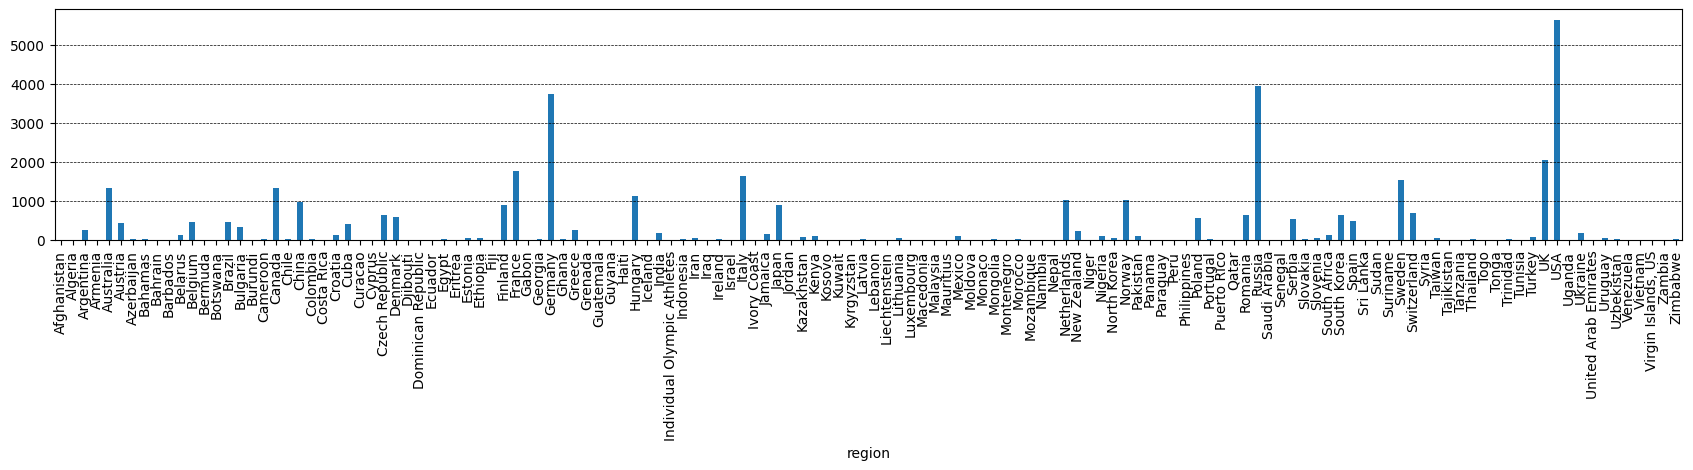

In [8]:
grafico3 = fusionado.groupby("region").sum()
filtro3 = grafico3[grafico3.medalla>0]
plot3 = filtro3["medalla"].plot.bar(figsize=(21,3))
plot3.axhline(y=1000, color='black', linestyle='--', linewidth=0.5)
plot3.axhline(y=2000, color='black', linestyle='--', linewidth=0.5)
plot3.axhline(y=3000, color='black', linestyle='--', linewidth=0.5)
plot3.axhline(y=4000, color='black', linestyle='--', linewidth=0.5)
plot3.axhline(y=5000, color='black', linestyle='--', linewidth=0.5)

## Gráfico 4: Temporada y Año.

<Axes: xlabel='Year'>

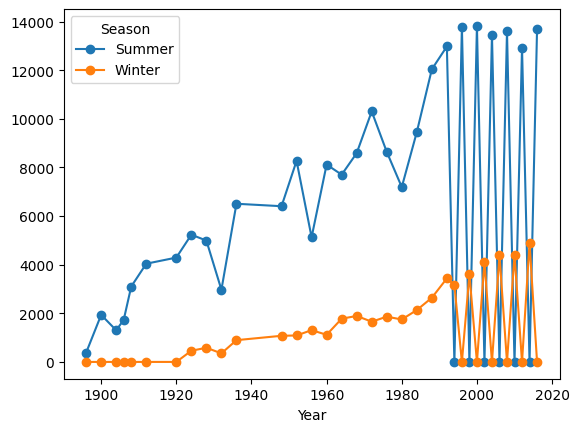

In [9]:
grafico4 = fusionado.groupby(["Year", "Season"]).size().unstack(fill_value=0)
grafico4.plot(marker="o")